# Wqk–Wov comparison: GD-trained COMBINED model vs hand-constructed W\*

**Models compared (same architecture instance, dim-matched, bias included):**
- **GD**: this folder's combined-parametrization checkpoints (`train_combined.py` → `models/model_x_{α}.pth`).
  Each attention layer is parametrized DIRECTLY by the circuits `W_qk` (= W_qᵀW_k) and `W_ov` (= W_o·W_v),
  so the usual within-layer gauge freedom does not exist — GD's learned `W_qk`/`W_ov` ARE the unique
  score/value circuits, directly comparable entry-wise.
- **W\***: `PerfectInductionTransformer` collapsed to the same products, with the **per-α optimal readout
  (σ, bN) already found in folder 6's `opening_up_trained_model.ipynb`** (`SIG_LIST`/`BN_LIST`) baked into
  `fc_out`: `weight ← σ·W`, `bias ← bN` on the 10 noise tokens (= the W\*-better readout, inside the model).

**Remaining (cross-layer) gauge.** Within a layer nothing is hidden anymore, but layer 1 still chooses an
arbitrary basis for its 220 output channels: `W_ov¹ → R·W_ov¹` can be compensated by layer 2 / fc_out on
the attn1-out coordinates. So layer-1 objects are compared raw, while layer-2 objects are folded back into
the fixed input coordinates through `P¹ = W_ov¹` before comparing. σ/bN live only in `fc_out`, so they
affect the functional check but none of the M_QK / M_OV objects.

In [5]:
# ── SETTINGS ──────────────────────────────────────────────────────────────────
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

F6         = '/home/hariguru/ashutosh/ICL/6. understanding what gradient descent is firuring out'
F7         = '/home/hariguru/ashutosh/ICL/7. unique_Wqk_Wok_test.ipynb'
DATA_DIR   = os.path.join(F6, 'dataset')      # same data as folders 6/8
MODELS_DIR = os.path.join(F7, 'models')       # THIS folder's combined (W_qk, W_ov) checkpoints

# shared box: pick the GPU with the most free memory right now (nvidia-smi,
# so no CUDA context is created on the other GPUs)
import subprocess
def _freest_gpu():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=memory.free',
                              '--format=csv,noheader,nounits'],
                             capture_output=True, text=True).stdout.split()
        return max(range(len(out)), key=lambda i: int(out[i]))
    except Exception:
        return 0
DEVICE     = f'cuda:{_freest_gpu()}' if torch.cuda.is_available() else 'cpu'

N_SEQS      = 200      # sequences per threshold for the CE comparison
TOKEN_START = 100      # CE window: tokens 100–200 (same as folder 6)
TOKEN_END   = 200
ATTN_DIM    = 220      # must match train_combined.py

# Per-α optimal W*-better readout (σ, bN) — taken AS-IS from folder 6's
# opening_up_trained_model.ipynb (SIG_LIST / BN_LIST). Baked into fc_out below.
THRESHOLDS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
SIG_LIST   = [3.0, 3.0, 4.0, 4.5, 5.0, 5.0, 6.0, 6.0, 6.0]
BN_LIST    = [3.0, 2.0, 2.0, 1.5, 1.5, 1.0, 1.0, 0.5, -0.5]
WBETTER_PAR = {round(t, 1): (s, b) for t, s, b in zip(THRESHOLDS, SIG_LIST, BN_LIST)}

device = torch.device(DEVICE)

# ── Trained model (must match train_combined.py: W_qk / W_ov circuits) ─────────
class CombinedAttentionBlock(nn.Module):
    '''scores = (x·W_qk)·xᵀ/√out ;  attn_out = softmax(scores)·(x·W_ovᵀ).
    W_qk [in,in] and W_ov [out,in] ARE the gauge-invariant circuits.'''
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.input_dim  = input_dim
        self.output_dim = output_dim
        self.W_qk = nn.Parameter(torch.empty(input_dim, input_dim))
        self.W_ov = nn.Parameter(torch.empty(output_dim, input_dim))
        nn.init.xavier_uniform_(self.W_qk)
        nn.init.xavier_uniform_(self.W_ov)
    def forward(self, x, mask=None):
        scores = torch.bmm(x @ self.W_qk, x.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores = scores + mask
        attn_out = torch.bmm(F.softmax(scores, dim=-1), x @ self.W_ov.t())
        return torch.cat([x, attn_out], dim=-1), scores

class DisentangledTransformerCombined(nn.Module):
    def __init__(self, total_vocab, seq_len, attn_dim, bias=False):
        super().__init__()
        self.total_vocab = total_vocab
        self.seq_len     = seq_len
        self.attn_dim    = attn_dim
        self.initial_dim = total_vocab + seq_len
        self.layer1 = CombinedAttentionBlock(self.initial_dim, attn_dim)
        self.layer2 = CombinedAttentionBlock(self.initial_dim + attn_dim, attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * attn_dim, total_vocab, bias=bias)
    def forward(self, x, return_attn=False):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, a1 = self.layer1(s, mask)
        s, a2 = self.layer2(s, mask)
        logits = self.fc_out(s)
        return (logits, [a1, a2]) if return_attn else logits

# ── PerfectInductionTransformer W* (same construction as folder 6) ────────────
class _ConcatAttn(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        s = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: s = s + mask
        return torch.cat([x, self.W_o(torch.bmm(F.softmax(s, dim=-1), V))], dim=-1)

class PerfectInductionTransformer(nn.Module):
    def __init__(self, total_vocab, seq_len, vocab_set1):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len; self.vocab_set1 = vocab_set1
        self.initial_dim = total_vocab + seq_len; self.attn_dim = self.initial_dim
        self.layer1 = _ConcatAttn(self.initial_dim, self.attn_dim)
        self.layer2 = _ConcatAttn(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, total_vocab, bias=False)
        self._set_weights()
    def _set_weights(self):
        V = self.total_vocab; T = self.seq_len; D = self.attn_dim; V_r = self.vocab_set1
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        T1 = torch.zeros(D, D)
        for k in range(V_r, V): T1[k, :] = -1e9
        for tq in range(T):
            for tk in range(T):
                T1[V + tk, V + tq] = -1e9 if tq == tk else -20.0 * (tq - tk)
        self.layer1.W_k.weight.data = T1.t()
        Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
        self.layer1.W_v.weight.data = Wv1
        self.layer1.W_o.weight.data = torch.eye(D)
        in2 = D + D
        Wq2 = torch.zeros(D, in2)
        Wq2[:V_r, :V_r]    = torch.eye(V_r) * (D ** 0.5) * 1000.0
        Wq2[:V_r, D:D+V_r] = torch.eye(V_r) * (D ** 0.5) * 50.0
        for v in range(V): Wq2[V_r, v] = (D ** 0.5) * 10.0
        self.layer2.W_q.weight.data = Wq2
        Wk2 = torch.zeros(D, in2); Wk2[:V, D:D+V] = torch.eye(V)
        for v in range(V_r, V): Wk2[V_r, v] = -50000.0
        self.layer2.W_k.weight.data = Wk2
        Wv2 = torch.zeros(D, in2); Wv2[:V, :V] = torch.eye(V)
        self.layer2.W_v.weight.data = Wv2
        self.layer2.W_o.weight.data = torch.eye(D)
        Wfc = torch.zeros(V, in2 + D); Wfc[:V, in2:in2+V] = torch.eye(V)
        self.fc_out.weight.data = Wfc
    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s = self.layer1(s, mask); s = self.layer2(s, mask)
        return self.fc_out(s)

# ── Loaders ───────────────────────────────────────────────────────────────────
def load_data(split, thr, n_cap=N_SEQS):
    blob = torch.load(os.path.join(DATA_DIR, split, f'data_x_{thr}.pt'), weights_only=False)
    N    = min(n_cap, blob['x'].shape[0])
    blob['x'] = blob['x'][:N]; blob['y'] = blob['y'][:N]
    if 'transitions' in blob: blob['transitions'] = blob['transitions'][:N]
    return blob['x'], blob['y'], int(blob['seq_len']), int(blob['total_vocab']), blob

def load_gd(thr, seq_len, total_vocab):
    '''This folder's combined-parametrization checkpoint (train_combined.py).'''
    model = DisentangledTransformerCombined(total_vocab, seq_len, ATTN_DIM, bias=True).to(device)
    model.load_state_dict(torch.load(os.path.join(MODELS_DIR, f'model_x_{thr}.pth'),
                                     map_location=device, weights_only=True))
    model.eval(); return model

def build_wstar(thr, seq_len, total_vocab, vocab_set1):
    '''W* with the per-α optimal readout baked in: logits = σ·L + bN·noise_mask
    (folder 6's W*-better, found there — NOT re-fitted here). With the bias term
    the constructed net has the SAME parameterisation as the trained one.'''
    ws = PerfectInductionTransformer(total_vocab, seq_len, vocab_set1)
    sig, bn = WBETTER_PAR[round(thr, 1)]
    fc = nn.Linear(ws.fc_out.in_features, total_vocab, bias=True)
    fc.weight.data = ws.fc_out.weight.data * sig
    fc.bias.data   = torch.zeros(total_vocab)
    fc.bias.data[vocab_set1:] = bn
    ws.fc_out = fc
    return ws.to(device).eval()

print(f'device={device}\nGD models={MODELS_DIR}\ndata={DATA_DIR}')

device=cuda:1
GD models=/home/hariguru/ashutosh/ICL/7. unique_Wqk_Wok_test.ipynb/models
data=/home/hariguru/ashutosh/ICL/6. understanding what gradient descent is firuring out/dataset


In [6]:
# ── COMBINED W* construction: collapse the hand W* into (W_qk, W_ov) circuits ───
# Verification: take the SAME PerfectInductionTransformer weights, but pre-multiply
# the four separate matrices into the gauge-invariant combined circuits used by the
# GD model (CombinedAttentionBlock):
#   W_qk  = W_qᵀ·W_k          (both layers)            -> score geometry
#   W_ov  = W_o·W_v           (layer 1)                -> value/output circuit
#   W_ovu = σ · unembed·W_o·W_v   (layer 2)            -> OV folded with the readout
# fc_out reads only attn2[:V] (Wfc = eye on cols [in2:in2+V]), so folding the
# unembedding = keeping the first V rows of W_o·W_v and scaling by σ.  σ (sig) and
# the noise bias bN are kept EXACTLY as build_wstar -> logits match the separate
# construction up to float round-off, hence an identical CE curve.
class WStarCombined(nn.Module):
    def __init__(self, total_vocab, seq_len, M_qk1, M_ov1, M_qk2, M_ovu2, bias, d1, d2):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len
        self.d1 = d1; self.d2 = d2
        self.register_buffer('M_qk1',  M_qk1)    # 220×220
        self.register_buffer('M_ov1',  M_ov1)    # 220×220
        self.register_buffer('M_qk2',  M_qk2)    # 440×440
        self.register_buffer('M_ovu2', M_ovu2)   # V×440  (already ×σ, unembed-folded)
        self.register_buffer('bias',   bias)     # V
    @torch.no_grad()
    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        # layer 1 — combined W_qk / W_ov
        sc1 = torch.bmm(s @ self.M_qk1, s.transpose(1, 2)) / (self.d1 ** 0.5) + mask
        a1  = torch.bmm(F.softmax(sc1, dim=-1), s @ self.M_ov1.t())
        s1  = torch.cat([s, a1], dim=-1)
        # layer 2 — combined W_qk, OV folded with σ·unembedding -> logits directly
        sc2 = torch.bmm(s1 @ self.M_qk2, s1.transpose(1, 2)) / (self.d2 ** 0.5) + mask
        logits = torch.bmm(F.softmax(sc2, dim=-1), s1 @ self.M_ovu2.t()) + self.bias
        return logits

def build_wstar_combined(thr, seq_len, total_vocab, vocab_set1):
    '''Same hand W* as build_wstar, but with the within-layer circuits collapsed to
    the combined (W_qk, W_ov) parametrization (layer-2 OV folded with σ·unembed).'''
    ws = PerfectInductionTransformer(total_vocab, seq_len, vocab_set1)   # CPU
    sig, bn = WBETTER_PAR[round(thr, 1)]
    L1, L2 = ws.layer1, ws.layer2
    # nn.Linear.weight is [out,in] and y = x·Wᵀ, so:
    #   scores = (x·Wqᵀ)(x·Wkᵀ)ᵀ = x·(WqᵀWk)·xᵀ   -> W_qk = Wqᵀ·Wk
    #   out    = softmax·(x·Wvᵀ)·Woᵀ = softmax·(x·(WoWv)ᵀ) -> W_ov = Wo·Wv
    M_qk1  = L1.W_q.weight.data.t() @ L1.W_k.weight.data    # 220×220
    M_ov1  = L1.W_o.weight.data     @ L1.W_v.weight.data    # 220×220
    M_qk2  = L2.W_q.weight.data.t() @ L2.W_k.weight.data    # 440×440
    M_ov2  = L2.W_o.weight.data     @ L2.W_v.weight.data    # 220×440
    M_ovu2 = sig * M_ov2[:total_vocab, :]                   # fold unembed (first V rows) ×σ
    bias   = torch.zeros(total_vocab); bias[vocab_set1:] = bn
    m = WStarCombined(total_vocab, seq_len, M_qk1, M_ov1, M_qk2, M_ovu2, bias,
                      L1.output_dim, L2.output_dim)
    return m.to(device).eval()

print('build_wstar_combined ready — collapses W* into combined (W_qk, W_ov) circuits.')

build_wstar_combined ready — collapses W* into combined (W_qk, W_ov) circuits.


--- test : separate vs combined W* ---


/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


  α=0.1  W*-sep=2.5861  W*-comb=2.5861  |Δ|=0.00e+00  GD=2.6150
  α=0.2  W*-sep=2.6510  W*-comb=2.6510  |Δ|=0.00e+00  GD=2.7235
  α=0.3  W*-sep=2.6544  W*-comb=2.6544  |Δ|=0.00e+00  GD=2.7447
  α=0.4  W*-sep=2.5779  W*-comb=2.5779  |Δ|=0.00e+00  GD=2.6815
  α=0.5  W*-sep=2.4787  W*-comb=2.4787  |Δ|=0.00e+00  GD=2.6004
  α=0.6  W*-sep=2.3036  W*-comb=2.3036  |Δ|=0.00e+00  GD=2.5146
  α=0.7  W*-sep=2.1054  W*-comb=2.1054  |Δ|=0.00e+00  GD=2.3019
  α=0.8  W*-sep=1.8390  W*-comb=1.8390  |Δ|=4.88e-08  GD=1.9999
  α=0.9  W*-sep=1.5111  W*-comb=1.5111  |Δ|=9.77e-08  GD=1.5891

max |W*-sep − W*-comb| = 9.77e-08


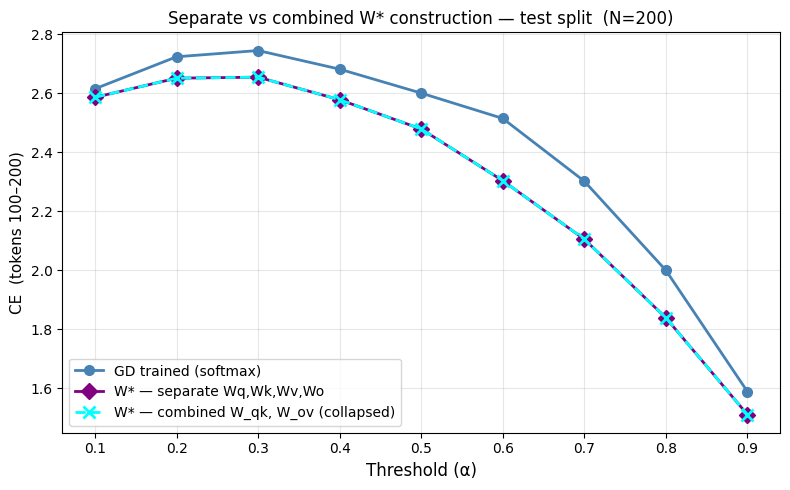

In [7]:
# ── Plot: combined W* construction vs the separate Wq/Wk/Wv/Wo construction ─────
# Same σ/bN, same data, same CE window — ONLY the parametrization changes (combined
# products instead of the four separate matrices).  The two purple/cyan curves must
# lie exactly on top of each other; GD shown for reference.  Self-contained (does
# not depend on the later eval cell), so it can run right after this construction.
SPLIT_C = 'test'      # 'test' or 'train'

@torch.no_grad()
def _ce(model, x, y, V, bs=128):
    tot, n = 0.0, 0
    for i in range(0, x.shape[0], bs):
        xb = x[i:i+bs].to(device); yb = y[i:i+bs].to(device)
        lo = model(xb)[:, TOKEN_START:TOKEN_END, :]
        yw = yb[:, TOKEN_START:TOKEN_END]
        tot += F.cross_entropy(lo.reshape(-1, V), yw.reshape(-1), reduction='sum').item()
        n   += yw.numel()
    return tot / n

sep_ce, comb_ce, gd_ce = [], [], []
print(f'--- {SPLIT_C} : separate vs combined W* ---')
for thr in THRESHOLDS:
    x, y, seq_len, V, blob = load_data(SPLIT_C, thr)
    V_sig = int(blob['vocab_set1'])
    ws_s = build_wstar(thr, seq_len, V, V_sig)            # separate Wq,Wk,Wv,Wo
    ws_c = build_wstar_combined(thr, seq_len, V, V_sig)   # combined W_qk, W_ov
    gd   = load_gd(thr, seq_len, V)
    s, c, g = _ce(ws_s, x, y, V), _ce(ws_c, x, y, V), _ce(gd, x, y, V)
    sep_ce.append(s); comb_ce.append(c); gd_ce.append(g)
    print(f'  α={thr:.1f}  W*-sep={s:.4f}  W*-comb={c:.4f}  |Δ|={abs(s-c):.2e}  GD={g:.4f}')
    del ws_s, ws_c, gd

print(f'\nmax |W*-sep − W*-comb| = {max(abs(a-b) for a, b in zip(sep_ce, comb_ce)):.2e}')

plt.figure(figsize=(8, 5))
plt.plot(THRESHOLDS, gd_ce,   'o-',  color='steelblue', lw=2, ms=7, label='GD trained (softmax)')
plt.plot(THRESHOLDS, sep_ce,  'D-',  color='purple',    lw=2, ms=8,
         label='W* — separate Wq,Wk,Wv,Wo')
plt.plot(THRESHOLDS, comb_ce, 'x--', color='cyan',      lw=2, ms=9, mew=2,
         label='W* — combined W_qk, W_ov (collapsed)')
plt.xlabel('Threshold (α)', fontsize=12)
plt.ylabel(f'CE  (tokens {TOKEN_START}–{TOKEN_END})', fontsize=11)
plt.title(f'Separate vs combined W* construction — {SPLIT_C} split  (N={N_SEQS})', fontsize=12)
plt.legend(fontsize=10); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [8]:
# ── Functional comparison: GD vs W*(σ,bN) vs ctx-count vs ideal-α ──────────────
# Evaluates BOTH splits once (results cached in `results`); toggle the plot in the
# next cell.  ctx-count / ideal-α are folder 6's implementations, copied verbatim.
@torch.no_grad()
def ce(model, x, y, V, batch_size=128):
    total, n = 0.0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(device); yb = y[i:i+batch_size].to(device)
        logits = model(xb)[:, TOKEN_START:TOKEN_END, :]
        yw = yb[:, TOKEN_START:TOKEN_END]
        total += F.cross_entropy(logits.reshape(-1, V), yw.reshape(-1), reduction='sum').item()
        n += yw.numel()
    return total / n

def alpha_ce(blob, alpha):
    x_np = blob['x'].numpy(); y_np = blob['y'].numpy()
    V = int(blob['total_vocab']); V_sig = int(blob['vocab_set1'])
    n_noise = V - V_sig; B = x_np.shape[0]
    trans_counts = np.zeros((B, V, V_sig), dtype=np.float64)
    pending      = np.zeros((B, V), dtype=np.float64)
    last_ruled   = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok_col = x_np[:, col]; is_ruled = tok_col < V_sig
        ri = np.where(is_ruled)[0]
        if len(ri):
            rt = tok_col[ri]
            oh = (np.arange(V_sig) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_ruled)[0]
        if len(ni): pending[ni, tok_col[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    eps = 0.01; total_ce, n_tok = 0.0, 0
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]; is_sig_q = v < V_sig
        query = np.where(is_sig_q, v, np.maximum(last_ruled, 0))
        cnt = trans_counts[np.arange(B), query]; cnt_s = cnt + eps
        tot_s = cnt_s.sum(axis=1, keepdims=True)
        p = np.zeros((B, V), dtype=np.float64)
        p[:, :V_sig] = cnt_s / tot_s * alpha; p[:, V_sig:] = (1.0 - alpha) / n_noise
        p = np.maximum(p, 1e-12)
        total_ce += (-np.log(p[np.arange(B), y_np[:, t]])).sum(); n_tok += B
        _step(t)
    return total_ce / n_tok

def ideal_alpha_ce(blob, alpha):
    x_np = blob['x'].numpy(); y_np = blob['y'].numpy(); trans = blob['transitions']
    V = int(blob['total_vocab']); V_sig = int(blob['vocab_set1'])
    n_noise = V - V_sig; B = x_np.shape[0]
    trans_arr = np.array([[trans[b][v] for v in range(V_sig)] for b in range(B)], dtype=np.int64)
    total_ce, n_tok = 0.0, 0
    last_sig = np.zeros(B, dtype=np.int64)
    for t in range(TOKEN_END):
        is_sig = x_np[:, t] < V_sig
        last_sig = np.where(is_sig, x_np[:, t], last_sig)
        if t < TOKEN_START: continue
        s0 = trans_arr[np.arange(B), last_sig, 0]; s1 = trans_arr[np.arange(B), last_sig, 1]
        p = np.zeros((B, V), dtype=np.float64)
        p[:, V_sig:] = (1.0 - alpha) / n_noise
        p[np.arange(B), s0] += alpha / 2; p[np.arange(B), s1] += alpha / 2
        total_ce += (-np.log(np.maximum(p[np.arange(B), y_np[:, t]], 1e-12))).sum(); n_tok += B
    return total_ce / n_tok

results = {'train': {}, 'test': {}}
for split in ('train', 'test'):
    print(f'--- {split} ---')
    for thr in THRESHOLDS:
        x, y, seq_len, V, blob = load_data(split, thr)
        V_sig = int(blob['vocab_set1'])
        gd = load_gd(thr, seq_len, V)
        ws = build_wstar(thr, seq_len, V, V_sig)
        r = dict(gd=ce(gd, x, y, V), wstar=ce(ws, x, y, V),
                 ctx=alpha_ce(blob, thr), ideal=ideal_alpha_ce(blob, thr))
        results[split][thr] = r
        print(f"  α={thr:.1f}  GD={r['gd']:.4f}  W*={r['wstar']:.4f}  "
              f"ctx={r['ctx']:.4f}  ideal={r['ideal']:.4f}")
        del gd, ws
print('\nEvaluation complete — toggle the plot in the next cell.')

--- train ---


  α=0.1  GD=2.5888  W*=2.5672  ctx=2.5611  ideal=2.4629
  α=0.2  GD=2.6781  W*=2.6562  ctx=2.5909  ideal=2.4809
  α=0.3  GD=2.6645  W*=2.6490  ctx=2.5282  ideal=2.4318
  α=0.4  GD=2.6161  W*=2.5865  ctx=2.4149  ideal=2.3347
  α=0.5  GD=2.5288  W*=2.4719  ctx=2.2698  ideal=2.1950
  α=0.6  GD=2.4846  W*=2.3108  ctx=2.0717  ideal=2.0001
  α=0.7  GD=2.2723  W*=2.1130  ctx=1.8556  ideal=1.7918
  α=0.8  GD=1.9365  W*=1.8477  ctx=1.5686  ideal=1.5090
  α=0.9  GD=1.5751  W*=1.5355  ctx=1.2438  ideal=1.1904
--- test ---
  α=0.1  GD=2.6150  W*=2.5861  ctx=2.5789  ideal=2.4693
  α=0.2  GD=2.7235  W*=2.6510  ctx=2.5805  ideal=2.4815
  α=0.3  GD=2.7447  W*=2.6544  ctx=2.5313  ideal=2.4290
  α=0.4  GD=2.6815  W*=2.5779  ctx=2.4090  ideal=2.3374
  α=0.5  GD=2.6004  W*=2.4787  ctx=2.2741  ideal=2.1964
  α=0.6  GD=2.5146  W*=2.3036  ctx=2.0673  ideal=2.0048
  α=0.7  GD=2.3019  W*=2.1054  ctx=1.8465  ideal=1.7845
  α=0.8  GD=1.9999  W*=1.8390  ctx=1.5668  ideal=1.5097
  α=0.9  GD=1.5891  W*=1.5111  ctx=

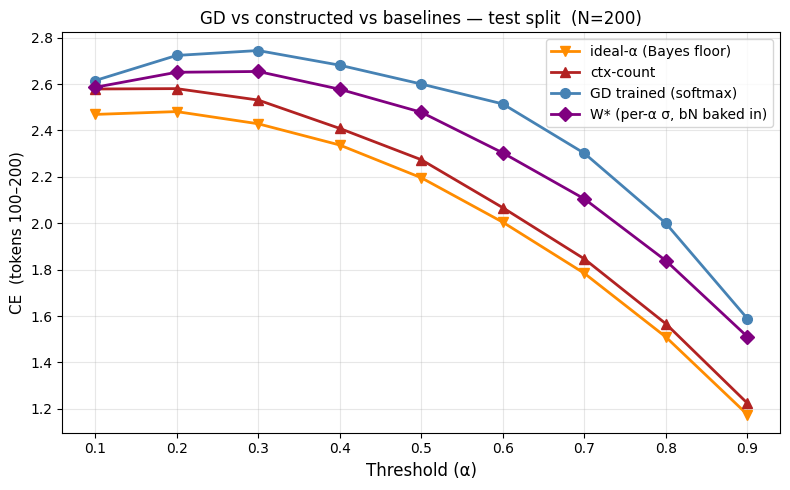

In [9]:
# ── Plot: toggle SPLIT ('test' / 'train') and any curve on/off ──────────────────
SPLIT = 'test'           # 'test' or 'train'
SHOW  = dict(ideal=True, ctx=True, gd=True, wstar=True)

SPECS = [('ideal', 'ideal-α (Bayes floor)',     'v-', 'darkorange'),
         ('ctx',   'ctx-count',                 '^-', 'firebrick'),
         ('gd',    'GD trained (softmax)',      'o-', 'steelblue'),
         ('wstar', 'W* (per-α σ, bN baked in)', 'D-', 'purple')]
plt.figure(figsize=(8, 5))
for k, lab, st, col in SPECS:
    if not SHOW.get(k): continue
    plt.plot(THRESHOLDS, [results[SPLIT][t][k] for t in THRESHOLDS], st,
             color=col, linewidth=2, markersize=7, label=lab)
plt.xlabel('Threshold (α)', fontsize=12)
plt.ylabel(f'CE  (tokens {TOKEN_START}–{TOKEN_END})', fontsize=11)
plt.title(f'GD vs constructed vs baselines — {SPLIT} split  (N={N_SEQS})', fontsize=12)
plt.legend(fontsize=10); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## What we compare (all in the fixed token⊕position input coordinates)

| object | size | meaning | W\* prediction |
|---|---|---|---|
| `M_QK¹` | 220×220 | layer-1 score geometry | pos-pos block = "previous position" band |
| `M_OV¹ = P¹` | 220×220 | what layer 1 writes | token block ≈ I (copy attended token) |
| `B_sa = A_sa·P¹` tok block | 20×20 | **induction match**: query = current input token, key = *previous*-token of candidate position | ≈ scale·I on signal tokens |
| `C = W_U(attn2)·M_OV²` (folded) | 20×440 | **copy circuit**: attended token → its own logit | token cols ≈ σ·I |

GD's `W_qk`/`W_ov` are read off the checkpoint directly (no products to form — the parametrization is
already gauge-fixed within each layer). `A = M_QK² (440×440)` splits into blocks over
`cat[input(220), attn1out(220)]`; every attn1out side is composed with `P¹ = W_ov¹` so the one remaining
(cross-layer) basis freedom cancels out. W\*'s hard ±1e9 gates are masked
(shown white); colour scales are per-panel robust percentiles — the **pattern** is the comparable thing,
not the magnitude.

In [10]:
# ── Gauge-invariant products + detail threshold ────────────────────────────────
THR = 0.9          # threshold inspected in detail below

x_c, y_c, seq_len, V, blob_c = load_data('test', THR)
V_sig    = int(blob_c['vocab_set1'])
gd_model = load_gd(THR, seq_len, V)
ws_model = build_wstar(THR, seq_len, V, V_sig)

def MQK(blk):
    # combined block: W_qk IS the circuit (same /√out scaling as the forward pass);
    # separate block (W*): collapse W_qᵀW_k — identical convention, so directly comparable.
    if hasattr(blk, 'W_qk'):
        return (blk.W_qk / (blk.output_dim ** 0.5)).detach().cpu().numpy()
    D = blk.W_q.weight.shape[0]
    return (blk.W_q.weight.t() @ blk.W_k.weight / (D ** 0.5)).detach().cpu().numpy()

def MOV(blk):
    if hasattr(blk, 'W_ov'):
        return blk.W_ov.detach().cpu().numpy()
    return (blk.W_o.weight @ blk.W_v.weight).detach().cpu().numpy()

def view(M, gate=1e6):
    M = np.array(M, dtype=np.float64, copy=True)
    M[np.abs(M) > gate] = np.nan        # hide W* hard logic gates
    return M

def cos(A, B):
    '''Cosine similarity on the finite (gate-masked) entries — scale-invariant.'''
    a, b = view(A).ravel(), view(B).ravel()
    m = np.isfinite(a) & np.isfinite(b)
    if not m.any(): return float('nan')
    a, b = a[m], b[m]
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return float(a @ b / (na * nb)) if na > 0 and nb > 0 else float('nan')

def mats(model):
    '''All gauge-invariant objects; layer-2 ones folded back into INPUT coords via P¹.'''
    P1 = MOV(model.layer1)                       # 220×220: input -> attn1-out coords
    A  = MQK(model.layer2)                       # 440×440 on cat[input, attn1out]
    D0 = P1.shape[0]
    B_ss = A[:D0, :D0]
    B_sa = A[:D0, D0:] @ P1                      # query=input token, key=prev-token (folded)
    B_as = P1.T @ A[D0:, :D0]
    B_aa = P1.T @ A[D0:, D0:] @ P1
    OV2  = MOV(model.layer2)                     # 220×440
    WU   = model.fc_out.weight.detach().cpu().numpy()       # V×660
    C    = WU[:, 2*D0:] @ OV2                    # logit circuit through attn2: V×440
    C    = np.concatenate([C[:, :D0], C[:, D0:] @ P1], axis=1)   # fold attn1 block
    return dict(MQK1=MQK(model.layer1), MOV1=P1,
                B_ss=B_ss, B_sa=B_sa, B_as=B_as, B_aa=B_aa, C=C)

GD, WS = mats(gd_model), mats(ws_model)
print(f'THR={THR}  seq_len={seq_len}  V={V}  V_sig={V_sig}')

THR=0.9  seq_len=200  V=20  V_sig=10


GD   M_QK¹ pos-pos diag means (offset 0..-5): [-0.    1.93 -0.   -0.31 -0.44 -0.37]   cos(M_OV¹ tok, I) = -0.033
W*   M_QK¹ pos-pos diag means (offset 0..-5): [  nan  -20.  -40.  -60.  -80. -100.]   cos(M_OV¹ tok, I) = 1.000


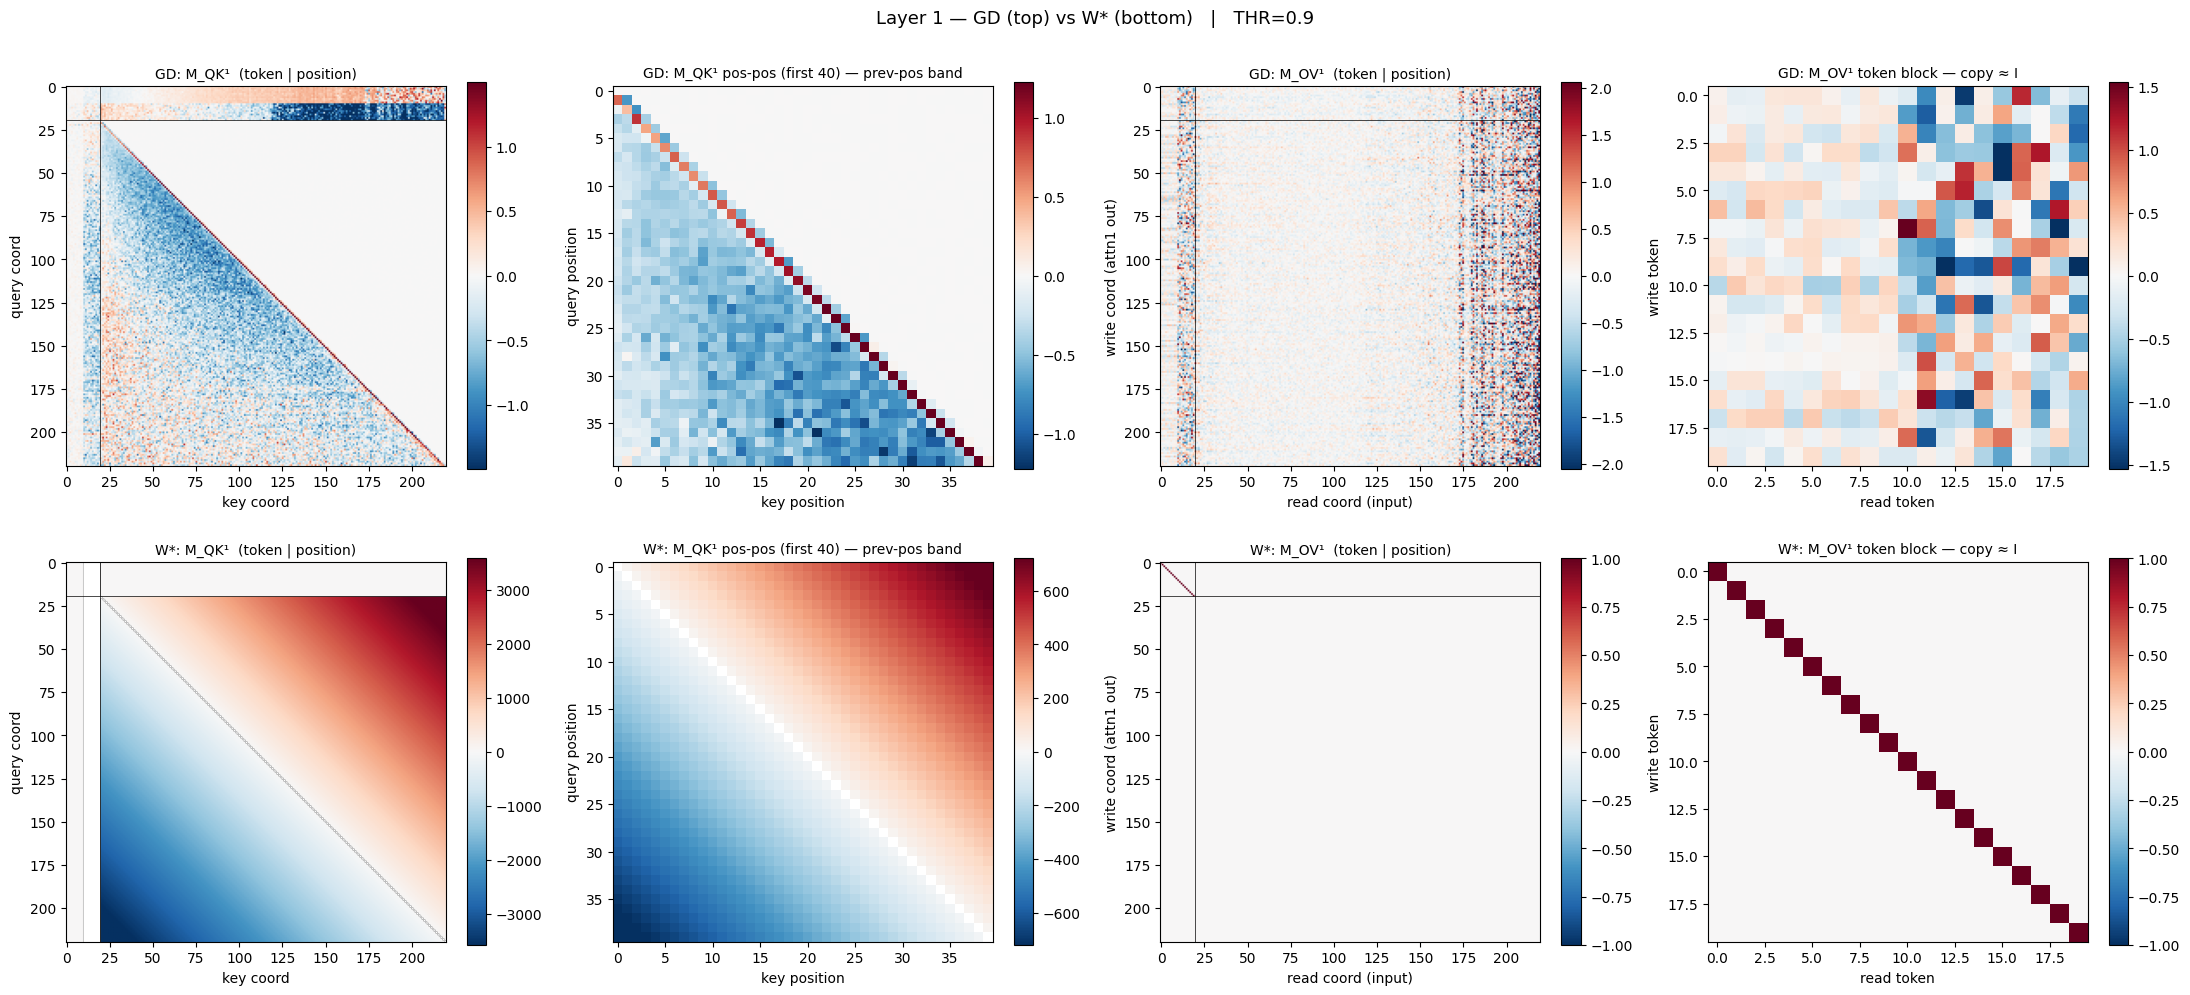

In [41]:
# ── Layer 1: M_QK¹ and M_OV¹ — GD (top) vs W* (bottom) ─────────────────────────
import warnings

def _show(ax, M, title, xlab='key coord', ylab='query coord'):
    q = np.nanpercentile(np.abs(M), 99)
    if not np.isfinite(q) or q == 0: q = 1.0
    im = ax.imshow(M, cmap='RdBu_r', vmin=-q, vmax=q)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xlab); ax.set_ylabel(ylab)
    plt.colorbar(im, ax=ax, fraction=.046)

fig, ax = plt.subplots(2, 4, figsize=(22, 10))
for row, (name, M) in enumerate([('GD', GD), ('W*', WS)]):
    mqk, mov = view(M['MQK1']), view(M['MOV1'])
    _show(ax[row, 0], mqk, f'{name}: M_QK¹  (token | position)')
    ax[row, 0].axhline(V - .5, color='k', lw=.5); ax[row, 0].axvline(V - .5, color='k', lw=.5)
    _show(ax[row, 1], mqk[V:, V:][:40, :40],
          f'{name}: M_QK¹ pos-pos (first 40) — prev-pos band', 'key position', 'query position')
    _show(ax[row, 2], mov, f'{name}: M_OV¹  (token | position)',
          'read coord (input)', 'write coord (attn1 out)')
    ax[row, 2].axhline(V - .5, color='k', lw=.5); ax[row, 2].axvline(V - .5, color='k', lw=.5)
    _show(ax[row, 3], mov[:V, :V], f'{name}: M_OV¹ token block — copy ≈ I',
          'read token', 'write token')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')        # offset-0 diagonal is all-NaN for W*
        band = [np.nanmean(np.diagonal(mqk[V:, V:], offset=-d)) for d in range(6)]
    print(f'{name:3s}  M_QK¹ pos-pos diag means (offset 0..-5): {np.round(band, 2)}   '
          f'cos(M_OV¹ tok, I) = {cos(M["MOV1"][:V, :V], np.eye(V)):.3f}')
plt.suptitle(f'Layer 1 — GD (top) vs W* (bottom)   |   THR={THR}', y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

GD   cos(B_sa sig-block, I) = 0.928   cos(C sig-block, I) = 0.947
W*   cos(B_sa sig-block, I) = 1.000   cos(C sig-block, I) = 1.000


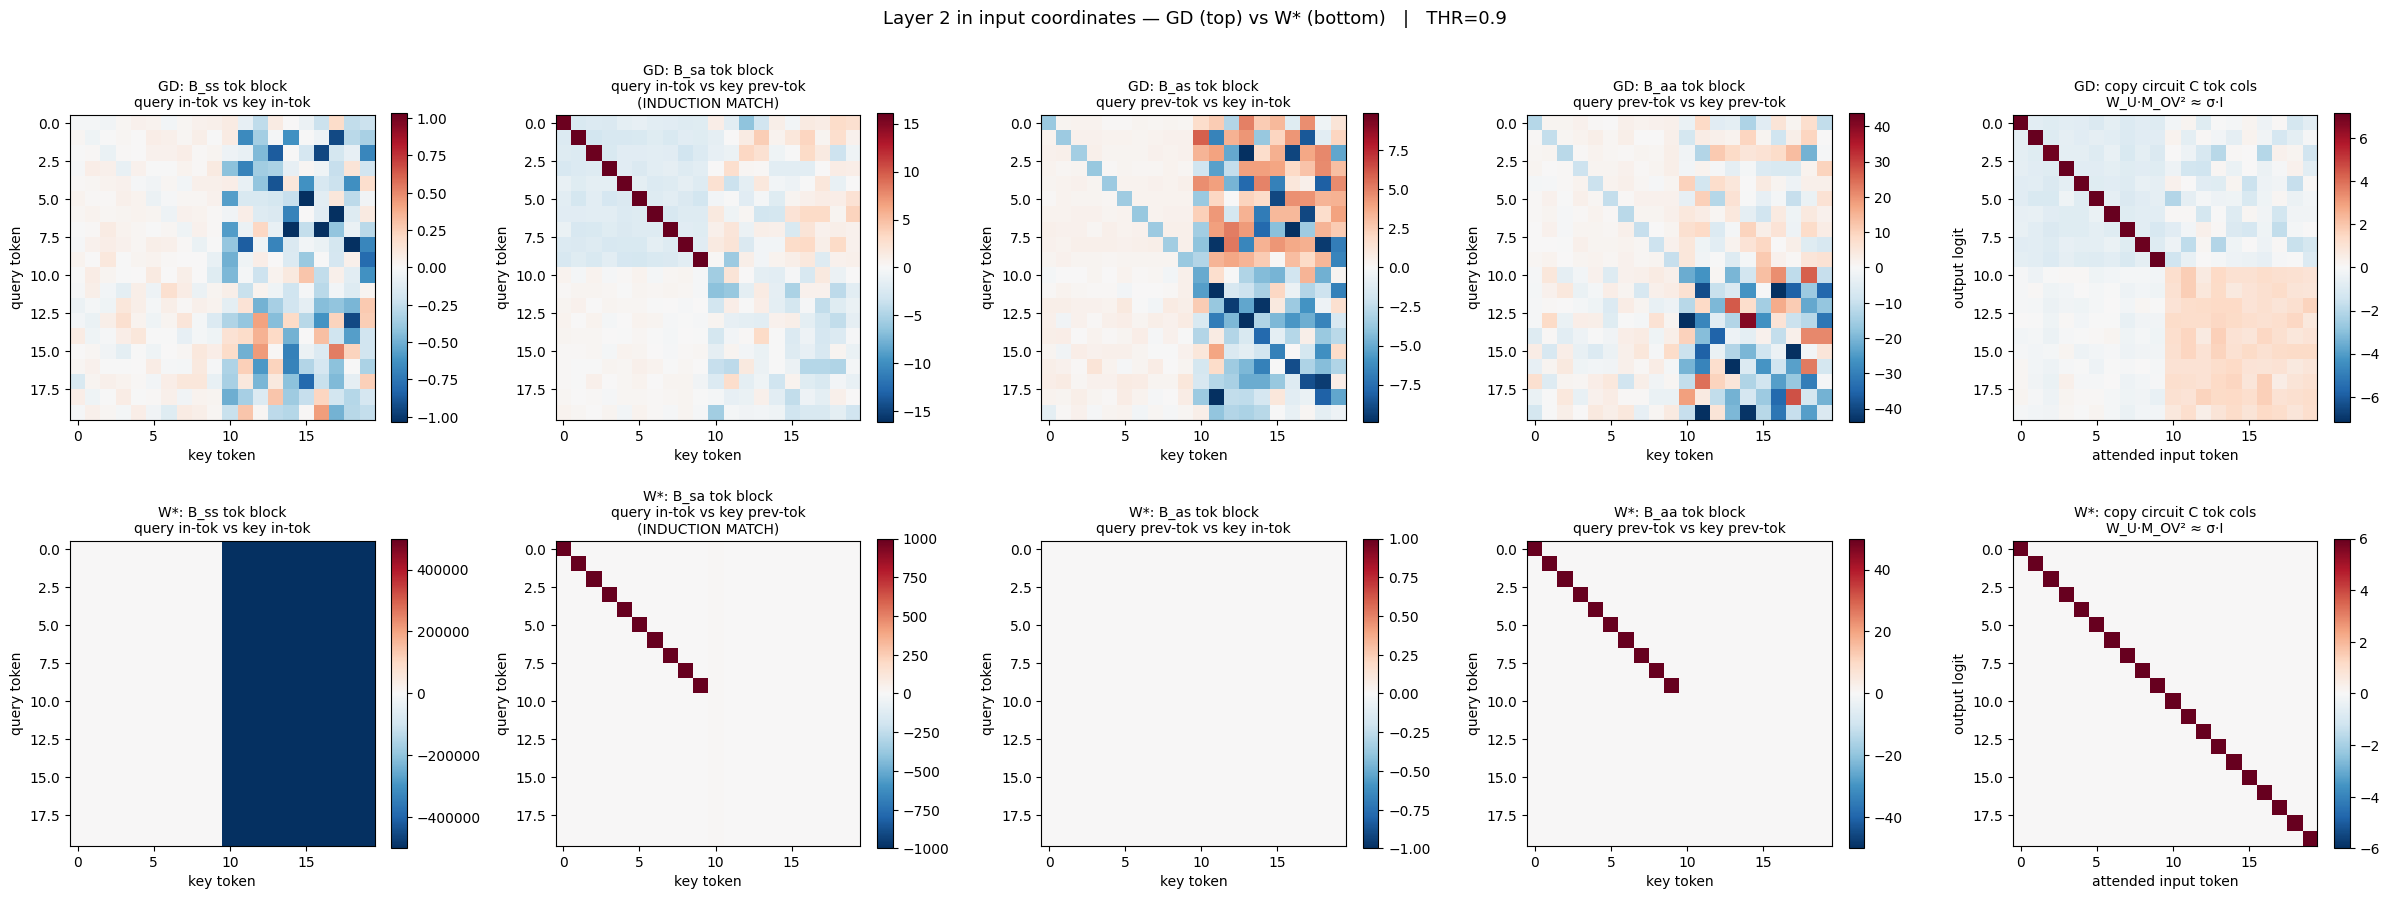

In [42]:
# ── Layer 2 (folded into input coords): induction match + copy circuit ─────────
# B_ss for W* shows the −5·10⁵ noise-filter columns (query trigger × key gate) —
# it dominates that panel's scale; the comparable structure is in B_sa and C.
blocks = [('B_ss', 'query in-tok vs key in-tok'),
          ('B_sa', 'query in-tok vs key prev-tok\n(INDUCTION MATCH)'),
          ('B_as', 'query prev-tok vs key in-tok'),
          ('B_aa', 'query prev-tok vs key prev-tok')]
fig, ax = plt.subplots(2, 5, figsize=(24, 9))
for row, (name, M) in enumerate([('GD', GD), ('W*', WS)]):
    for col, (key, lab) in enumerate(blocks):
        _show(ax[row, col], view(M[key][:V, :V]), f'{name}: {key} tok block\n{lab}',
              'key token', 'query token')
    _show(ax[row, 4], view(M['C'][:, :V]), f'{name}: copy circuit C tok cols\nW_U·M_OV² ≈ σ·I',
          'attended input token', 'output logit')

I_sig = np.eye(V_sig)
for name, M in [('GD', GD), ('W*', WS)]:
    print(f'{name:3s}  cos(B_sa sig-block, I) = {cos(M["B_sa"][:V_sig, :V_sig], I_sig):.3f}   '
          f'cos(C sig-block, I) = {cos(M["C"][:V_sig, :V_sig], I_sig):.3f}')
plt.suptitle(f'Layer 2 in input coordinates — GD (top) vs W* (bottom)   |   THR={THR}',
             y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

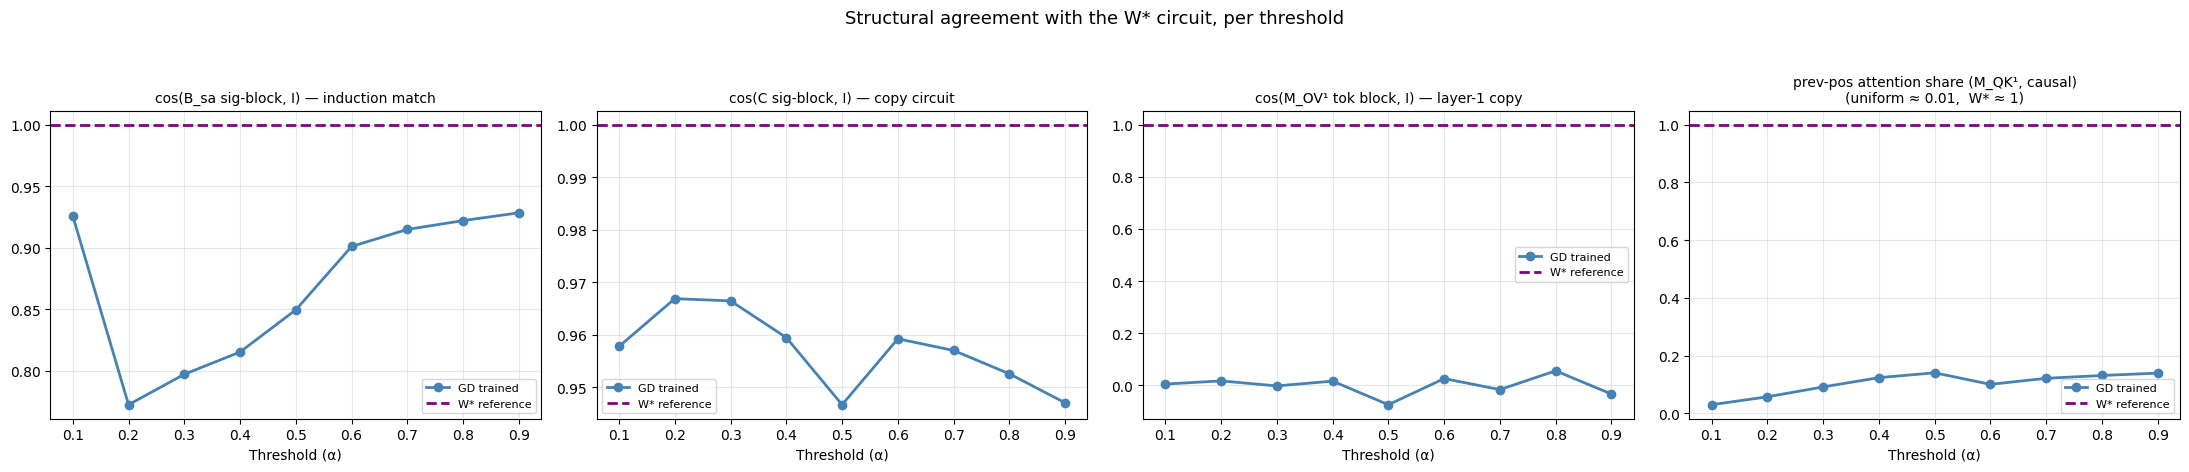

   α      ind     copy      ov1     prev
 0.1    0.926    0.958    0.005    0.030
 0.2    0.773    0.967    0.017    0.058
 0.3    0.797    0.966   -0.002    0.092
 0.4    0.815    0.959    0.016    0.124
 0.5    0.850    0.947   -0.074    0.141
 0.6    0.901    0.959    0.026    0.101
 0.7    0.915    0.957   -0.016    0.122
 0.8    0.922    0.953    0.056    0.131
 0.9    0.928    0.947   -0.033    0.140
  W*    1.000    1.000    1.000    1.000


In [43]:
# ── All thresholds: how W*-like is each GD model? ──────────────────────────────
ALL = {}
for thr in THRESHOLDS:
    m = load_gd(thr, seq_len, V)
    ALL[thr] = mats(m)
    del m
    # NOTE: torch.cuda.empty_cache() is currently broken on this box (driver quirk:
    # it raises CUDA OOM even after a trivial alloc) — del + allocator reuse is enough.

def metrics(M):
    # prev-position attention share: softmax of the pos-pos scores over CAUSAL keys
    # only (k < q), then the weight landed on k = q-1.  Uniform baseline ~ 1/q.
    pp = view(M['MQK1'])[V:, V:]
    pp = np.where(np.isfinite(pp), pp, -1e30)       # W* gates are -1e9 = -inf anyway
    share = []
    for q in range(1, pp.shape[0]):
        e = np.exp(pp[q, :q] - pp[q, :q].max())
        share.append(e[-1] / e.sum())
    return dict(ind =cos(M['B_sa'][:V_sig, :V_sig], I_sig),
                copy=cos(M['C'][:V_sig, :V_sig],   I_sig),
                ov1 =cos(M['MOV1'][:V, :V],        np.eye(V)),
                prev=float(np.mean(share)))

ws_m = metrics(WS)
gd_m = {t: metrics(ALL[t]) for t in THRESHOLDS}

SPECS = [('ind',       'cos(B_sa sig-block, I) — induction match'),
         ('copy',      'cos(C sig-block, I) — copy circuit'),
         ('ov1',       'cos(M_OV¹ tok block, I) — layer-1 copy'),
         ('prev',      'prev-pos attention share (M_QK¹, causal)\n(uniform ≈ 0.01,  W* ≈ 1)')]
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax_, (k, title) in zip(axes, SPECS):
    ax_.plot(THRESHOLDS, [gd_m[t][k] for t in THRESHOLDS], 'o-',
             color='steelblue', linewidth=2, label='GD trained')
    ax_.axhline(ws_m[k], color='purple', linestyle='--', linewidth=2, label='W* reference')
    ax_.set_xlabel('Threshold (α)'); ax_.set_title(title, fontsize=10)
    ax_.grid(alpha=0.3); ax_.legend(fontsize=8)
plt.suptitle('Structural agreement with the W* circuit, per threshold', y=1.04, fontsize=13)
plt.tight_layout(); plt.show()

print(f'{"α":>4s}  {"ind":>7s}  {"copy":>7s}  {"ov1":>7s}  {"prev":>7s}')
for t in THRESHOLDS:
    m = gd_m[t]
    print(f'{t:4.1f}  {m["ind"]:7.3f}  {m["copy"]:7.3f}  {m["ov1"]:7.3f}  {m["prev"]:7.3f}')
print(f'  W*  {ws_m["ind"]:7.3f}  {ws_m["copy"]:7.3f}  {ws_m["ov1"]:7.3f}  {ws_m["prev"]:7.3f}')

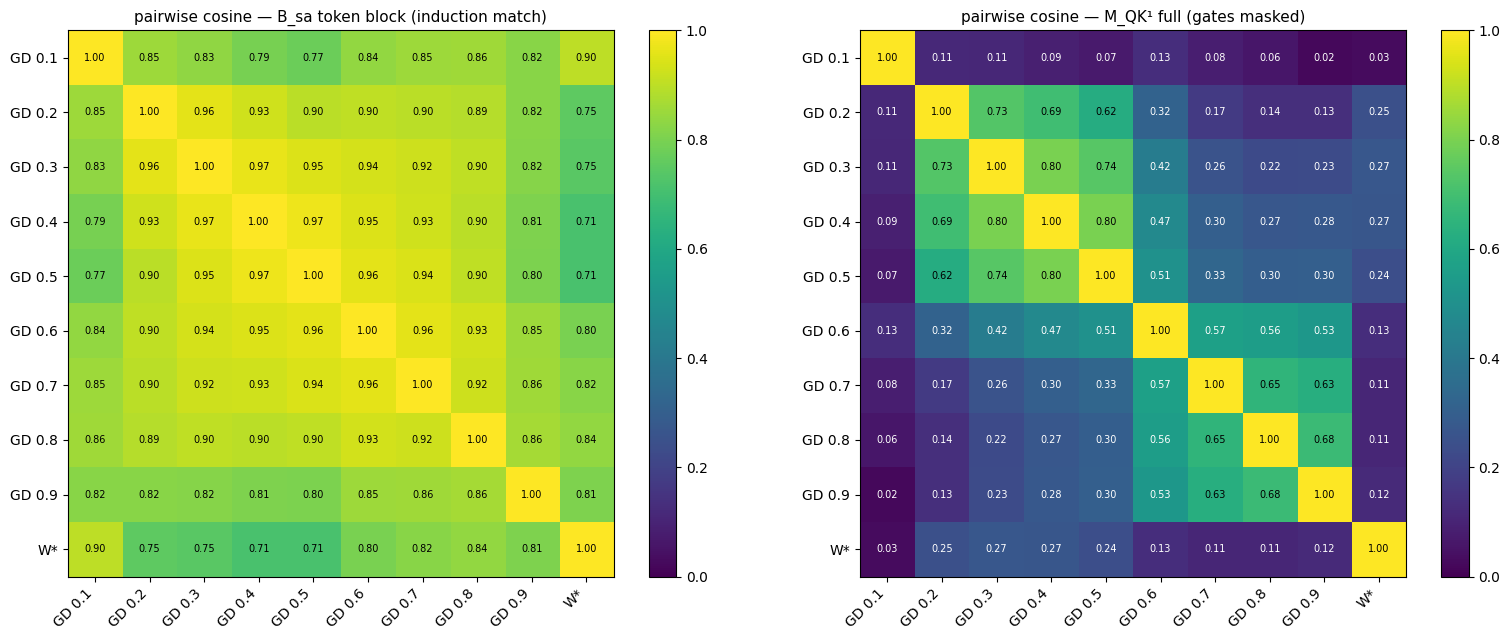

In [44]:
# ── Uniqueness: do all GD models (α=0.1…0.9) find the SAME circuit? ────────────
# Pairwise cosine similarity of the gauge-invariant objects across thresholds (+ W*).
names     = [f'GD {t:.1f}' for t in THRESHOLDS] + ['W*']
mats_list = [ALL[t] for t in THRESHOLDS] + [WS]

def pairwise(key, sub=None):
    n = len(mats_list); S = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(n):
            A, B = mats_list[i][key], mats_list[j][key]
            if sub is not None: A, B = A[:sub, :sub], B[:sub, :sub]
            S[i, j] = cos(A, B)
    return S

PANELS = [(pairwise('B_sa', V), 'B_sa token block (induction match)'),
          (pairwise('MQK1'),    'M_QK¹ full (gates masked)')]
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
for a, (S, title) in zip(ax, PANELS):
    vmin = min(0.0, np.nanmin(S))
    im = a.imshow(S, cmap='viridis', vmin=vmin, vmax=1)
    a.set_xticks(range(len(names))); a.set_xticklabels(names, rotation=45, ha='right')
    a.set_yticks(range(len(names))); a.set_yticklabels(names)
    a.set_title(f'pairwise cosine — {title}', fontsize=11)
    for i in range(len(names)):
        for j in range(len(names)):
            a.text(j, i, f'{S[i, j]:.2f}', ha='center', va='center', fontsize=7,
                   color='w' if S[i, j] < vmin + 0.6 * (1 - vmin) else 'k')
    plt.colorbar(im, ax=a, fraction=.046)
plt.tight_layout(); plt.show()